# Práctica de certamen — temperatura frente al tiempo
**Origen:** reelaboración breve del notebook de un compañero; **los datos adjuntos son simulados para practicar**, no el enunciado ni las mediciones reales del certamen. Se mantiene el recorrido: XY → semilog → transformación logarítmica → ajuste lineal.

## 1. Leer las cuatro columnas
Tiempo $t$ (s), incertidumbre $\delta t$ (s), temperatura $T$ (°C) e incertidumbre $\delta T$ (°C).

In [1]:
import numpy as np
import matplotlib.pyplot as plt
plt.style.use('bmh')

datos = np.genfromtxt('Temperatura-vs-tiempo_CON_INCERTIDUMBRES.txt', comments='#')
t, dt, T, dT = datos.T
print(f'{len(t)} observaciones; T inicial = {T[0]:.1f} °C')

16 observaciones; T inicial = 80.0 °C


## 2. XY lineal con incertidumbres
Las barras permiten ver la magnitud de la incertidumbre frente a la dispersión y al rango de variación.

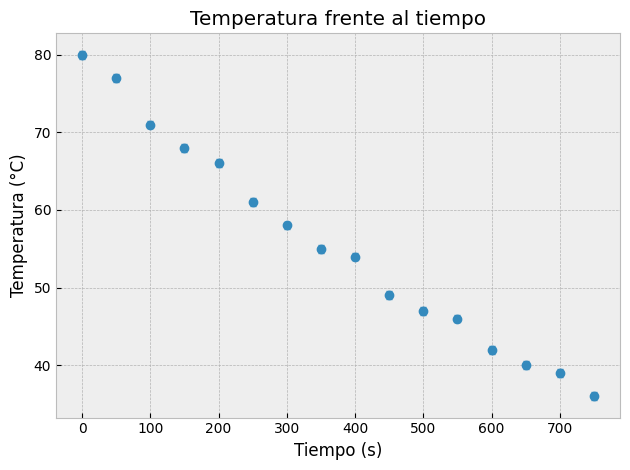

In [2]:
plt.errorbar(t, T, xerr=dt, yerr=dT, fmt='o', capsize=2)
plt.xlabel('Tiempo (s)')
plt.ylabel('Temperatura (°C)')
plt.title('Temperatura frente al tiempo')
plt.tight_layout();plt.show()

## 3. Comparar con eje vertical logarítmico
La escala semilog **no transforma los datos que guarda Python**; solo cambia su visualización.

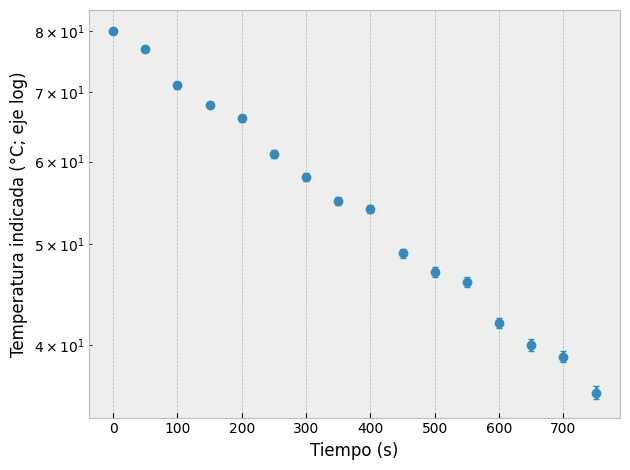

In [3]:
plt.errorbar(t, T, xerr=dt, yerr=dT, fmt='o', capsize=2)
plt.yscale('log')
plt.xlabel('Tiempo (s)')
plt.ylabel('Temperatura indicada (°C; eje log)')
plt.tight_layout();plt.show()

## 4. Transformar y ajustar
Como en el archivo del compañero, definimos $z(t)=\ln[T(t)/T(0)]$ y ajustamos $z(t)\approx mt+b$. Aquí el cociente es numéricamente positivo y adimensional, **pero usar °C en una ley exponencial no tiene justificación física general**: el cero Celsius es arbitrario. Este ajuste es un ejercicio matemático, no una demostración de la ley de enfriamiento.

ln(T/T0) ≈ (-0.00105365 s⁻¹) t + (0.00118854)


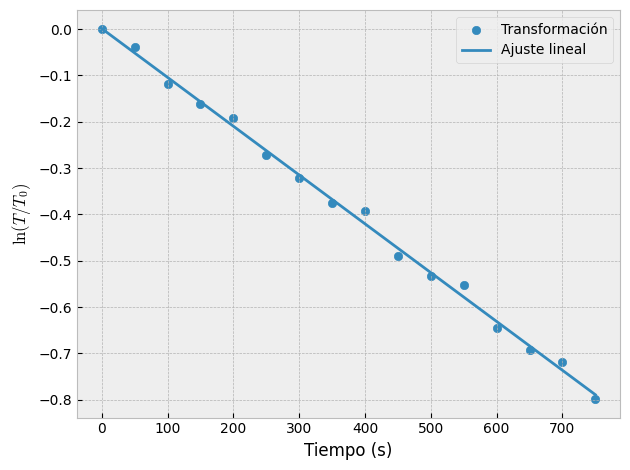

In [4]:
z = np.log(T / T[0])
pendiente, intercepto = np.polyfit(t, z, 1)
z_ajuste = pendiente*t + intercepto
print(f'ln(T/T0) ≈ ({pendiente:.6g} s⁻¹) t + ({intercepto:.6g})')
plt.scatter(t, z, label='Transformación')
plt.plot(t, z_ajuste, label='Ajuste lineal')
plt.xlabel('Tiempo (s)')
plt.ylabel(r'$\ln(T/T_0)$')
plt.legend();plt.tight_layout();plt.show()

## 5. Regresar al espacio original y comprobar el signo
De $\ln(T/T_0)=mt+b$ se obtiene **$T_{\mathrm{modelo}}(t)=T_0\exp(mt+b)$**. La pendiente negativa debe conservar su signo; en el notebook recibido aparecía un signo positivo por error al escribir el exponente.

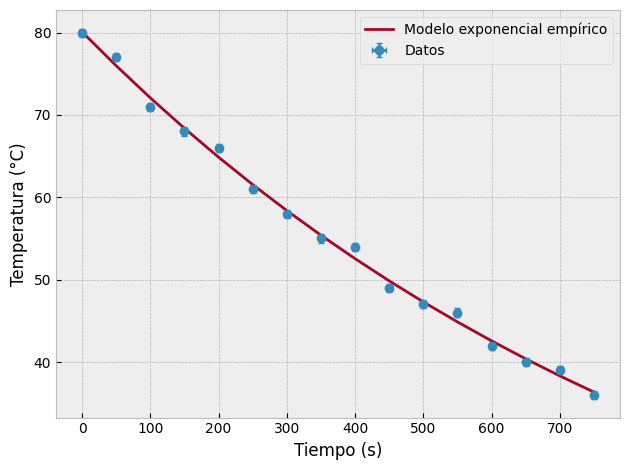

Pendiente negativa: True
Raíz del promedio de residuos² (°C): 0.7702790465571914


In [5]:
T_modelo = T[0]*np.exp(pendiente*t + intercepto)
plt.errorbar(t, T, yerr=dT, xerr=dt, fmt='o', capsize=2, label='Datos')
plt.plot(t, T_modelo, label='Modelo exponencial empírico')
plt.xlabel('Tiempo (s)');plt.ylabel('Temperatura (°C)')
plt.legend();plt.tight_layout();plt.show()
print('Pendiente negativa:', pendiente < 0)
print('Raíz del promedio de residuos² (°C):', np.sqrt(np.mean((T-T_modelo)**2)))

> **Alcance físico:** el enfriamiento de Newton se modela típicamente como $T(t)=T_{\rm amb}+(T(0)-T_{\rm amb})e^{-kt}$ y requiere conocer o ajustar $T_{\rm amb}$. Ni el archivo ni el ejercicio adjunto especifican ese dato. No debemos interpretar el ajuste en Celsius como una prueba de dicho modelo.

**Para practicar:** reconstruye $T(t)$ desde los parámetros sin consultar esta nota. Explica por qué la pendiente tiene unidades de $\mathrm{s}^{-1}$ y por qué el signo debe ser negativo para una curva decreciente.